# Preposition corrections in heritage and foreign-language Russian

Do heritage learners (HL) and foreign-language learners (FL) differ in the types of preposition corrections recorded in the annotated sample?

The data come from `rlc-goat`, a manually annotated sample from RULEC in RLC-GEC. I compare five categories across all selected errors, then compare insertion, deletion and substitution among preposition edits only. The five-category counts reproduce the existing `rlc-prepositions` summary; the edit-only comparison extends that analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")

## 1. Load the data

Save the CSV export of the `rlc-goat` sheet as `rlc-goat.csv` in the same folder as this notebook. Run the notebook from that folder.

In [2]:
df = pd.read_csv("rlc-goat.csv", dtype=str, keep_default_na=False)
df.columns = df.columns.str.strip()
required = ["id", "sentence_id", "quote_preposition", "correction_preposition",
            "language_background", "level"]
assert set(required).issubset(df.columns), "Check the CSV column names."
assert df["id"].ne("").all() and df["id"].is_unique, "Check annotation IDs."
print("Rows:", len(df))
df["language_background"].value_counts()

Rows: 485


language_background
FL    310
HL    175
Name: count, dtype: int64

## 2. Classify the corrections

The dash `—` means no preposition; an empty cell means missing information. The annotation `(shared)` is removed before comparing labels. Multiword items and allomorphs remain separate as annotated.

Directions are from learner text to correction: an insertion repairs an omission, and a deletion removes an extra item. A retained preposition may accompany a case error.

In [3]:
def clean_preposition(value):
    value = " ".join(value.split())
    value = value.removesuffix("(shared)").strip()
    if value.lower() in ["", "na", "n/a", "nan", "none", "unknown", "unclear", "?"]:
        return None
    return value

for column in ["quote_preposition", "correction_preposition"]:
    df[column] = df[column].apply(clean_preposition)

def classify(row):
    before = row["quote_preposition"]
    after = row["correction_preposition"]
    if before is None or after is None:
        return "Unknown"
    if before == "—" and after == "—":
        return "Absent in both"
    if before == after:
        return "Retained"
    if before == "—":
        return "Inserted"
    if after == "—":
        return "Deleted"
    return "Substituted"

df["operation"] = df.apply(classify, axis=1)
valid = df["operation"].ne("Unknown") & df["language_background"].isin(["HL", "FL"])
print("Excluded rows:", (~valid).sum())
df = df[valid].copy()
groups = ["HL", "FL"]
operations = ["Absent in both", "Retained", "Inserted", "Deleted", "Substituted"]
edits = operations[2:]

Excluded rows: 0


## 3. Counts and percentages

Percentages are calculated within each group. The second table includes only actual preposition edits. Neither denominator includes all correct uses in the corpus.

In [4]:
counts = pd.crosstab(df["language_background"], df["operation"])
counts = counts.reindex(index=groups, columns=operations, fill_value=0)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100
display(counts)
display(percentages.round(1))

edit_counts = counts[edits]
edit_percentages = edit_counts.div(edit_counts.sum(axis=1), axis=0) * 100
display(edit_counts)
display(edit_percentages.round(1))
print("Percentage with any preposition edit:")
display((edit_counts.sum(axis=1) / counts.sum(axis=1) * 100).round(1))

operation,Absent in both,Retained,Inserted,Deleted,Substituted
language_background,,,,,
HL,81,61,13,15,5
FL,191,63,20,24,12


operation,Absent in both,Retained,Inserted,Deleted,Substituted
language_background,,,,,
HL,46.3,34.9,7.4,8.6,2.9
FL,61.6,20.3,6.5,7.7,3.9


operation,Inserted,Deleted,Substituted
language_background,,,
HL,13,15,5
FL,20,24,12


operation,Inserted,Deleted,Substituted
language_background,,,
HL,39.4,45.5,15.2
FL,35.7,42.9,21.4


Percentage with any preposition edit:


language_background
HL    18.9
FL    18.1
dtype: float64

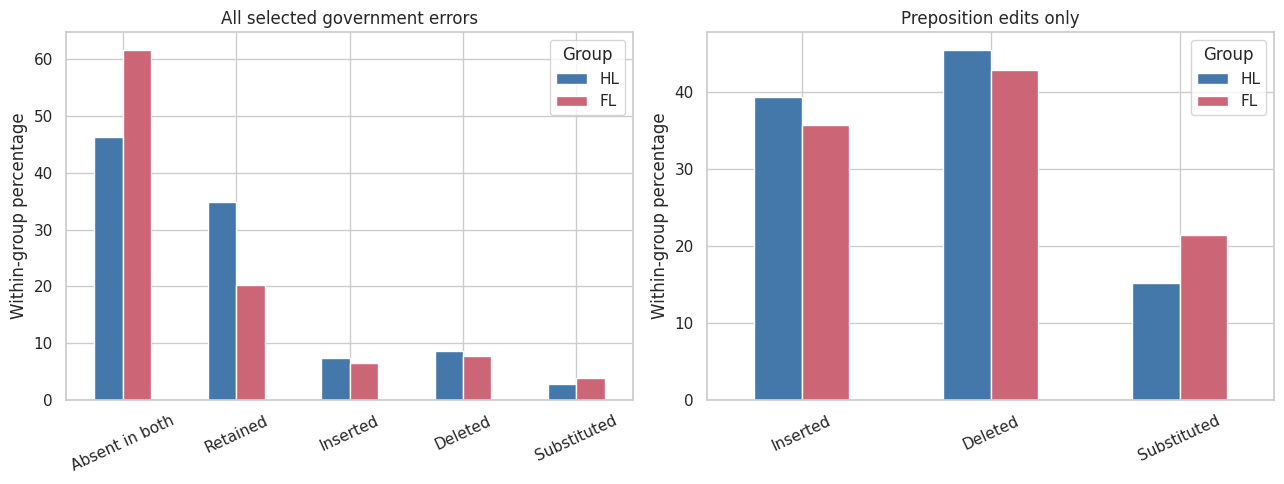

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
percentages.T.plot.bar(ax=axes[0], color=["#4477AA", "#CC6677"])
edit_percentages.T.plot.bar(ax=axes[1], color=["#4477AA", "#CC6677"])
axes[0].set_title("All selected government errors")
axes[1].set_title("Preposition edits only")
for ax in axes:
    ax.set_ylabel("Within-group percentage")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(title="Group")
plt.tight_layout()
plt.show()

## 4. Compare HL and FL

Pearson's chi-square test compares the category distributions. Cramér's V describes association strength. Expected counts are checked before interpreting the asymptotic p-values. Bonferroni correction is applied to the two main comparisons.

These tests assume independent observations. Repeated sentences are examined below; dependence between texts by the same writer cannot be addressed with these fields.

In [6]:
def compare(table):
    table = table.loc[:, table.sum() > 0]
    chi2, p, dof, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * min(table.shape[0]-1, table.shape[1]-1)))
    return {"chi2": chi2, "df": dof, "p": p, "Cramers_V": v,
            "minimum_expected": expected.min()}

results = pd.DataFrame([compare(counts), compare(edit_counts)],
                       index=["All five categories", "Edits only"])
results["p_adjusted"] = (results["p"] * 2).clip(upper=1)
results.round(4)

,chi2,df,p,Cramers_V,minimum_expected,p_adjusted
All five categories,14.5085,4,0.0058,0.1730,6.1340,0.0117
Edits only,0.5361,2,0.7649,0.0776,6.3034,1.0000


In [7]:
chi2, p, dof, expected = chi2_contingency(counts, correction=False)
contributions = ((counts - expected) ** 2 / expected).sum(axis=0)
display(contributions.round(2).rename("Chi-square contribution"))
print("Share from absent and retained categories:",
      round(contributions.iloc[:2].sum() / contributions.sum() * 100, 1), "%")

operation
Absent in both    4.69
Retained          9.24
Inserted          0.16
Deleted           0.10
Substituted       0.33
Name: Chi-square contribution, dtype: float64

Share from absent and retained categories: 96.0 %


## 5. Check repeated sentences

Three verified split sentence IDs are mapped to their original sentences. I select one random annotation per sentence with a fixed seed and repeat the comparisons. This is a sensitivity check, not a correction for repeated writers. Sparse expected counts make its p-values approximate.

In [8]:
parents = {"17011.1": "17011", "88002.1": "88002", "1360092.1": "1360092"}
df["sentence"] = df["sentence_id"].replace(parents)
assert df["sentence"].ne("").all(), "Missing sentence IDs."
print("Original sentences:", df["sentence"].nunique())
one_per_sentence = df.sample(frac=1, random_state=42).drop_duplicates("sentence")
sentence_counts = pd.crosstab(one_per_sentence["language_background"],
                             one_per_sentence["operation"])
sentence_counts = sentence_counts.reindex(index=groups, columns=operations, fill_value=0)
display(sentence_counts)
sentence_results = pd.DataFrame([compare(sentence_counts), compare(sentence_counts[edits])],
                                index=["All five categories", "Edits only"])
sentence_results.round(4)

Original sentences: 414


operation,Absent in both,Retained,Inserted,Deleted,Substituted
language_background,,,,,
HL,68,48,13,12,4
FL,166,55,18,20,10


,chi2,df,p,Cramers_V,minimum_expected
All five categories,10.7177,4,0.0299,0.1609,4.9034
Edits only,0.7343,2,0.6927,0.0977,5.2727


## 6. Proficiency levels

These descriptive tables show group composition by proficiency. Small subgroups limit interpretation; this is not a proficiency-controlled test.

operation                  Absent in both  Retained  Inserted  Deleted  \
language_background level                                                
FL                  AL                 91        21        14       11   
                    AM                 15         4         2        3   
                    IH                 38        19         3        5   
                    IM                 47        19         1        5   
HL                  AL                 35        27         3        6   
                    AM                 23        12         1        3   
                    IH                 21        20         5        4   
                    IM                  2         2         4        2   

operation                  Substituted  
language_background level               
FL                  AL               8  
                    AM               1  
                    IH               2  
                    IM               1  
HL                  AL               1  
                    AM               0  
                    IH               2  
                    IM               2

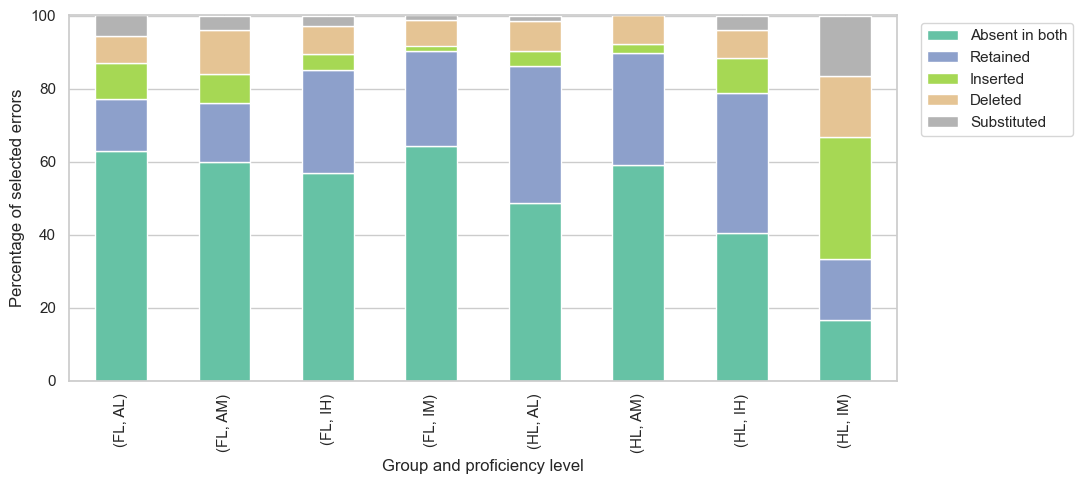

In [9]:
level_counts = pd.crosstab([df["language_background"], df["level"]], df["operation"])
level_counts = level_counts.reindex(columns=operations, fill_value=0)
display(level_counts)
level_percentages = level_counts.div(level_counts.sum(axis=1), axis=0) * 100
level_percentages.plot.bar(stacked=True, figsize=(11, 5), colormap="Set2")
plt.ylabel("Percentage of selected errors")
plt.xlabel("Group and proficiency level")
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## 7. Which prepositions change?

These frequencies describe the selected errors, not the difficulty of individual prepositions. The latter would require counts of correct uses too.

correction_preposition
в             7
о             5
к             4
на            4
из            3
по            2
для           2
с             2
через         1
между         1
за            1
в качестве    1
Name: Insertions, dtype: int64

quote_preposition
в         9
для       6
о         6
на        5
по        3
с         3
у         1
к         1
против    1
как       1
от        1
под       1
об        1
Name: Deletions, dtype: int64

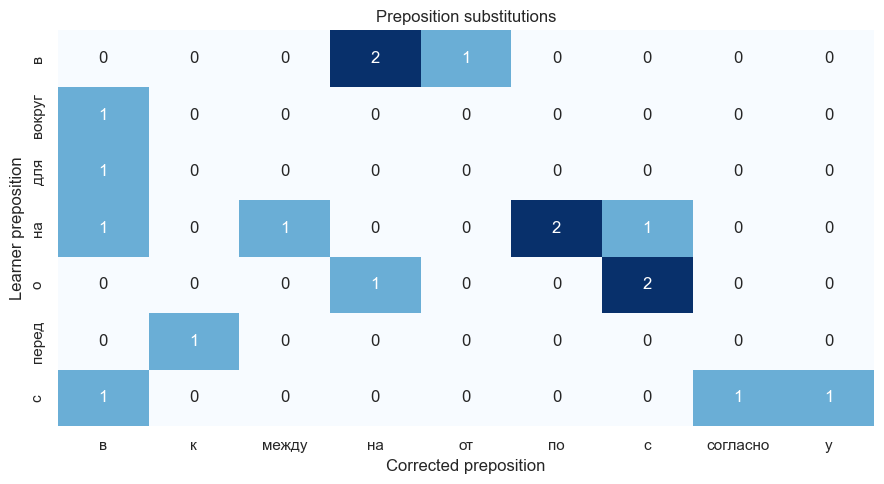

In [10]:
inserted = df[df["operation"] == "Inserted"]["correction_preposition"].value_counts()
deleted = df[df["operation"] == "Deleted"]["quote_preposition"].value_counts()
display(inserted.rename("Insertions"))
display(deleted.rename("Deletions"))

substitutions = df[df["operation"] == "Substituted"]
pairs = pd.crosstab(substitutions["quote_preposition"], substitutions["correction_preposition"])
plt.figure(figsize=(9, 5))
sns.heatmap(pairs, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Corrected preposition")
plt.ylabel("Learner preposition")
plt.title("Preposition substitutions")
plt.tight_layout()
plt.show()

## 8. Conclusions

In the analysed snapshot, 33 of 175 HL observations (18.9%) and 56 of 310 FL observations (18.1%) involve a preposition edit. The five-category distributions differ, mainly because of the absent-in-both and retained categories. Among the 89 edits, the insertion/deletion/substitution comparison does not provide clear evidence of a group difference. A nonsignificant result does not establish equivalence.

The analysis concerns the composition of selected government errors, not overall error rates or learner accuracy. The small number of substitutions and possible dependence between observations limit generalisation.